In [2]:
#卷积层的计算，cross-correlation计算、padding、stride
import dnnlpy
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F #提供神经网络的运算函数，如relu、softmax、crossentropy
from torch import Tensor

dnnlpy.set_matplotlib_format('highdpi') #调用 dnnlpy 模块中的 set_matplotlib_format 方法，并将 highdpi 作为参数传进去。表示Jupyter绘图使用高清显示模式
print('PyTorch version:',torch.__version__)

PyTorch version: 2.12.0.dev20260408+cu128


In [3]:
#二维互相关/卷积计算函数
def corr2d(x:Tensor,kernel:Tensor)->Tensor:
    #input和kernel不是二维则无法计算
    if x.ndim!=2 or kernel.ndim!=2:
        raise AssertionError('input and kernel must both be 2d Tensor.')

    #定义卷积核的宽高K_h, K_w，output的宽高h，w
    K_h, K_w = kernel.size()
    h = x.size(0) - K_h + 1
    w = x.size(1) - K_w + 1

    #input宽高<= 0则错误
    if h <= 0 or w <= 0:
        raise RuntimeError('`kernel` must not be larger than the input.')

    #创建空output
    output=x.new_empty(h,w) #x.new_empty继承x的dtype和device

    #局部窗口和kernel的对应元素相乘并求和
    for i in range(h):
        for j in range(w):
            window=x[i:i+K_h,j:j+K_w]
            output[i,j]=torch.sum(kernel*window)

    return output

#测试函数corr2d
x=torch.arange(9,dtype=torch.float32).view(3,3)
kernel=torch.tensor([[0.0,1.0],
                     [2.0,3.0]])
y=corr2d(x,kernel)
print('Inout:',x,sep='\n') #sep='\n'：指定两个输出内容Input和x之间使用换行符分隔
print('Kernel:',kernel,sep='\n')
print('Output:',y,sep='\n')

Inout:
tensor([[0., 1., 2.],
        [3., 4., 5.],
        [6., 7., 8.]])
Kernel:
tensor([[0., 1.],
        [2., 3.]])
Output:
tensor([[19., 25.],
        [37., 43.]])


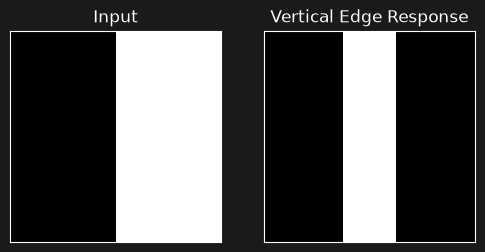

In [4]:
#可视化10*10图像经过卷积计算后输出8*8特征图
image = torch.zeros(10, 10)
image[:, 5:] = 1.0

kernel = torch.tensor(
    [
        [-1.0, 0.0, 1.0],
        [-1.0, 0.0, 1.0],
        [-1.0, 0.0, 1.0],
    ]
)
response = corr2d(image, kernel)

fig = plt.figure(1, figsize=(6, 3))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(image, cmap='gray', vmin=0, vmax=1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title('Input')
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(response, cmap='gray')
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title('Vertical Edge Response')
plt.show()

In [6]:
#padding:填充一格的前后对比
x=torch.arange(1,10,dtype=torch.float32)
x=x.view(1,1,3,3)
padded=F.pad(x,pad=(1,1,1,1)) #给x的填充顺序是(left, right, top, bottom)

print('Original input:',x[0,0],sep='\n') #x[0, 0]就是取出x的第一个batch和第一个channel，即3*3图像矩阵
print('After padding=1:',padded[0,0],sep='\n')

Original input:
tensor([[1., 2., 3.],
        [4., 5., 6.],
        [7., 8., 9.]])
After padding:
tensor([[0., 0., 0., 0., 0.],
        [0., 1., 2., 3., 0.],
        [0., 4., 5., 6., 0.],
        [0., 7., 8., 9., 0.],
        [0., 0., 0., 0., 0.]])


In [8]:
#stride:步长1和2的输出区别
x=torch.arange(1,26,dtype=torch.float32).view(1,1,5,5)
kernel=torch.ones(1,1,3,3)

stride1=F.conv2d(x,kernel,stride=1)
stride2=F.conv2d(x,kernel,stride=2)

print('Input shape:',x.shape)
print('Output shape with stride1:',stride1.shape)
print('Output shape with stride2:',stride2.shape)
print('Output with stride1:',stride1[0,0],sep='\n')
print('Output with stride2:',stride2[0,0],sep='\n')

Input shape: torch.Size([1, 1, 5, 5])
Output shape with stride1: torch.Size([1, 1, 3, 3])
Output shape with stride2: torch.Size([1, 1, 2, 2])
Output with stride1:
tensor([[ 63.,  72.,  81.],
        [108., 117., 126.],
        [153., 162., 171.]])
Output with stride2:
tensor([[ 63.,  81.],
        [153., 171.]])


In [10]:
#多通道输入
x=torch.tensor( #创建输入张量x，形状(2,3,3)，两个通道的3*3矩阵
    [
        [[1.0,2.0,3.0],[4.0,5.0,6.0],[7.0,8.0,9.0]],
        [[9.0,8.0,7.0],[6.0,5.0,4.0],[3.0,2.0,1.0]],
    ]
)
kernel=torch.tensor( #kernel形状(2,2,2)，两个通道的2*2矩阵
    [
        [[1.0,0.0],[0.0,1.0]],
        [[0.0,1.0],[1.0,0.0]],
    ]
)

#手动计算多通道卷积
actual=sum(corr2d(x[c],kernel[c]) for c in range(x.size(0))) #x.size(0)表示获取第0维大小，即2双通道，range(2)遍历输入张量的两个通道去做corrd2d计算。x[c],kernel[c]表示取第c个通道去卷积计算
#用pytorch自动计算卷积
expected=F.conv2d(x.unsqueeze(0),kernel.unsqueeze(0)) #x.unsqueeze(0)表示在第0维的位置增加一个新维度，即x=(2,3,3)加一个batch size维度成x=(1，2,3,3)
#比较手动与自动的计算结果
flag=torch.allclose(actual,expected[0,0]) #expected[0,0]表示取第1个batch，第1个输出通道

print('Manual output:', actual, sep='\n')
print('PyTorch output:', expected[0, 0], sep='\n')
print('Is manual output equal to PyTorch output?', flag)

Manual output:
tensor([[20., 20.],
        [20., 20.]])
PyTorch output:
tensor([[20., 20.],
        [20., 20.]])
Is manual output equal to PyTorch output? True
